# OCTMnist Dataset Exploration
Exploring the OCTMnist dataset for the MedMNIST extension of the Beyond Interpretability paper.

In [1]:
import medmnist
from medmnist import OCTMNIST
import torch
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

print(f'MedMNIST version: {medmnist.__version__}')

[HAMI-core Msg(464:140701241441600:libvgpu.c:839)]: Initializing.....


MedMNIST version: 3.0.2


## 1. Load Dataset

Using the 64x64 resolution for better results

In [4]:
# Load at 64x64 resolution
train_dataset = OCTMNIST(split='train', download=True, size=64, root='/home/jovyan/MedMNIST')
val_dataset   = OCTMNIST(split='val',   download=True, size=64, root='/home/jovyan/MedMNIST')
test_dataset  = OCTMNIST(split='test',  download=True, size=64, root='/home/jovyan/MedMNIST')

print(f'Train: {len(train_dataset)} samples')
print(f'Val:   {len(val_dataset)} samples')
print(f'Test:  {len(test_dataset)} samples')

CLASS_NAMES = train_dataset.info['label']
print(f'\nClasses: {CLASS_NAMES}')

100%|██████████| 312M/312M [00:01<00:00, 178MB/s]  


Train: 97477 samples
Val:   10832 samples
Test:  1000 samples

Classes: {'0': 'choroidal neovascularization', '1': 'diabetic macular edema', '2': 'drusen', '3': 'normal'}


## 2. Visualise Sample Images

/tmp/ipykernel_464/805869426.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  c = int(label)


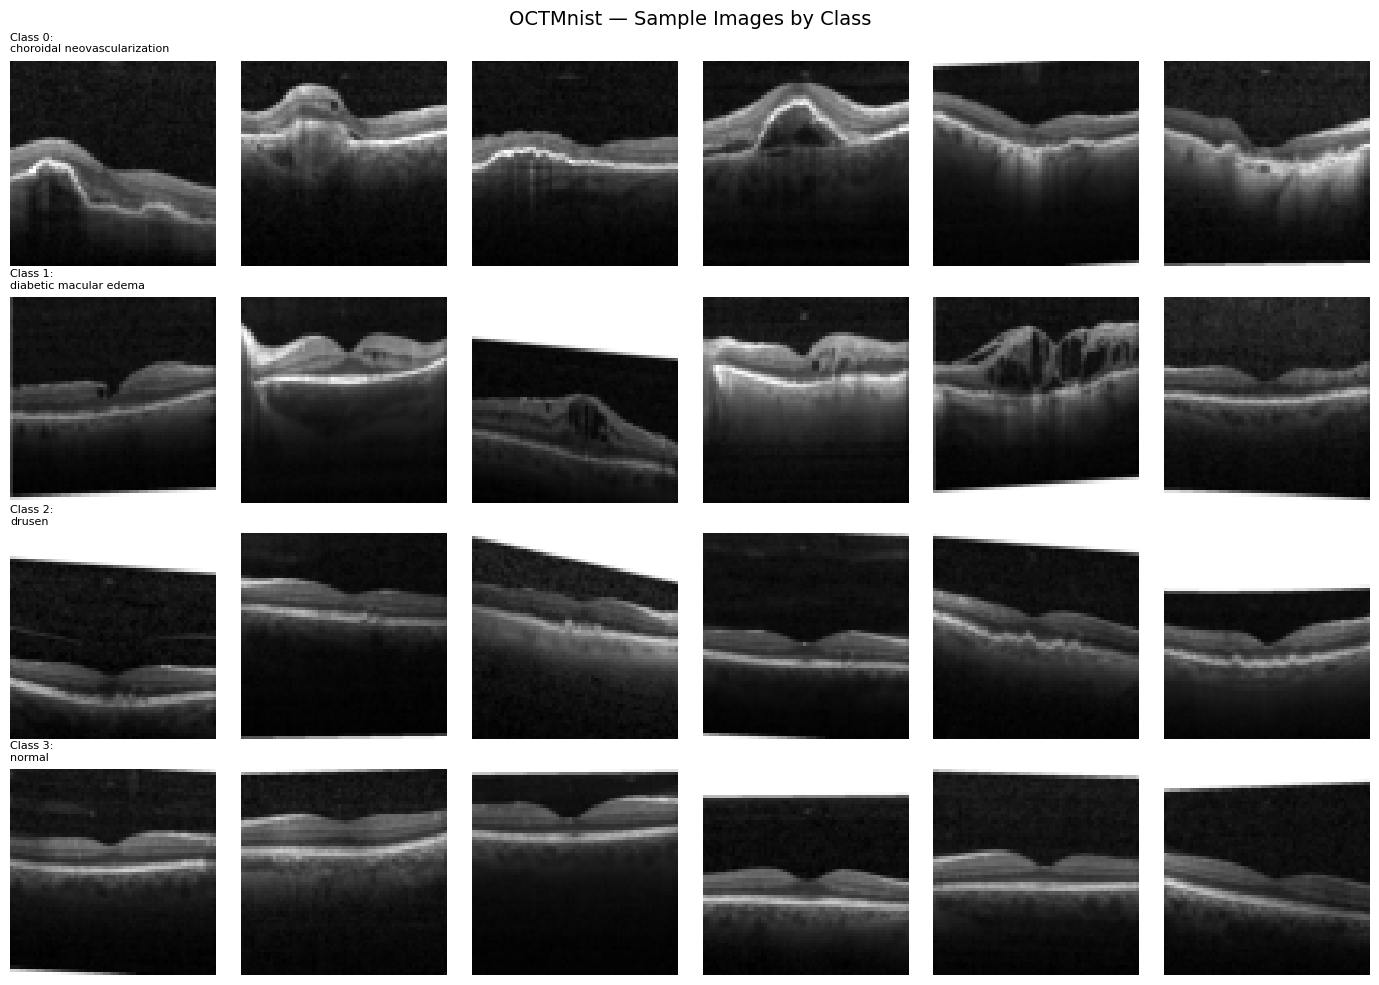

Saved octmnist_samples.png


In [6]:
fig, axes = plt.subplots(4, 6, figsize=(14, 10))
fig.suptitle('OCTMnist — Sample Images by Class', fontsize=14)

# Collect 6 examples per class
class_samples = {i: [] for i in range(4)}
for img, label in train_dataset:
    c = int(label)
    if len(class_samples[c]) < 6:
        class_samples[c].append(img)
    if all(len(v) == 6 for v in class_samples.values()):
        break

for row, (cls_idx, samples) in enumerate(class_samples.items()):
    cls_name = CLASS_NAMES[str(cls_idx)]
    for col, img in enumerate(samples):
        ax = axes[row][col]
        ax.imshow(np.array(img), cmap='gray')
        ax.axis('off')
        if col == 0:
            ax.set_title(f'Class {cls_idx}:\n{cls_name}', fontsize=8, loc='left')

plt.tight_layout()
plt.savefig('octmnist_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved octmnist_samples.png')

## 3. Class Distribution

/tmp/ipykernel_464/1708028974.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  train_labels = [int(label) for _, label in train_dataset]


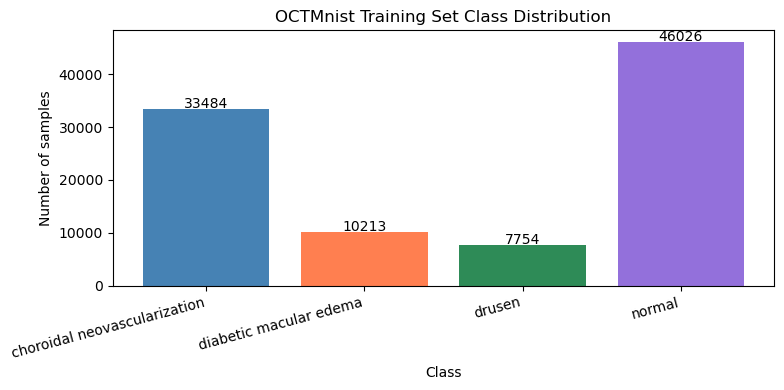


Class counts:
  choroidal neovascularization: 33484 (34.4%)
  diabetic macular edema: 10213 (10.5%)
  drusen: 7754 (8.0%)
  normal: 46026 (47.2%)


In [7]:
train_labels = [int(label) for _, label in train_dataset]
counts = Counter(train_labels)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([CLASS_NAMES[str(i)] for i in range(4)], 
              [counts[i] for i in range(4)],
              color=['steelblue', 'coral', 'seagreen', 'mediumpurple'])
ax.set_title('OCTMnist Training Set Class Distribution')
ax.set_ylabel('Number of samples')
ax.set_xlabel('Class')
for bar, count in zip(bars, [counts[i] for i in range(4)]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, 
            str(count), ha='center', fontsize=10)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('octmnist_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nClass counts:')
for i in range(4):
    print(f'  {CLASS_NAMES[str(i)]}: {counts[i]} ({counts[i]/len(train_labels)*100:.1f}%)')

## 4. Image Properties

In [11]:
img, label = train_dataset[0]
img_array = np.array(img)

print(f'Image type: {type(img)}')
print(f'Image size: {img.size}')
print(f'Array shape: {img_array.shape}')
print(f'Pixel range: [{img_array.min()}, {img_array.max()}]')
print(f'Channels: {train_dataset.info["n_channels"]} (grayscale)')
print(f'\nNote: ResNet-18 expects 3 channels')

Image type: <class 'PIL.Image.Image'>
Image size: (64, 64)
Array shape: (64, 64)
Pixel range: [6, 191]
Channels: 1 (grayscale)

Note: ResNet-18 expects 3 channels


## 5. Normalisation Statistics

In [15]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Compute mean and std for normalisation
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),  # repeat channel x3 for ResNet
    transforms.ToTensor()
])

tmp = OCTMNIST(split='train', download=True, size=64, root='/home/jovyan/MedMNIST', transform=transform)
loader = DataLoader(tmp, batch_size=1024, shuffle=False, num_workers=0)

mean = torch.zeros(3)
std = torch.zeros(3)
n = 0
for imgs, _ in loader:
    mean += imgs.mean(dim=[0,2,3]) * imgs.shape[0]
    std += imgs.std(dim=[0,2,3]) * imgs.shape[0]
    n += imgs.shape[0]

mean /= n
std /= n
print(f'Mean: {mean.tolist()}')
print(f'Std:  {std.tolist()}')
print('\nUse these values in the normalisation transform for pretraining.')

Mean: [0.18943294882774353, 0.18943294882774353, 0.18943294882774353]
Std:  [0.20710933208465576, 0.20710933208465576, 0.20710933208465576]

Use these values in the normalisation transform for pretraining.


## 6. Notes for Pipeline Adaptation

Key differences from CIFAR-100 that need to be handled:

| Property | CIFAR-100 | OCTMnist |
|----------|-----------|----------|
| Image size | 32×32 | 64×64 (or 28×28) |
| Channels | 3 (RGB) | 1 (grayscale) |
| Classes | 100 | 4 |
| Train samples | 50,000 | 97,477 |
| Random SC baseline | 1/100 = 1% | 1/4 = 25% |

**Required changes:**
1. Repeat grayscale channel ×3 for ResNet input
2. Update normalisation stats (computed above)
3. Update `num_classes` to 4 in linear probing config
4. Update crop size in augmentation config to match image size
5. Write a new dataloader that loads MedMNIST format